# Nettoyage des données logistiques

Groupe 3.
Participants notebook : Siyaman, Ilicia


Nous préparons les sept fichiers de `data/logistics`. Le but est de corriger les formats et les répétitions avant l'analyse. Nous conservons les données brutes et nous travaillons sur des copies.

Cette partie utilise le **CM1** : doublons, formats, catégories et valeurs manquantes. Les écarts entre les stocks et les mouvements seront étudiés dans le notebook d'analyse ; ils ne sont pas corrigés automatiquement ici.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dossier = Path("data/logistics")
fichiers = sorted(dossier.glob("*.csv"))
if len(fichiers) != 7:
    raise FileNotFoundError("Les sept fichiers de data/logistics sont nécessaires.")

raw = {f.stem: pd.read_csv(f) for f in fichiers}

## 1. Regarder les fichiers avant de les modifier

Nous comptons les lignes, les doublons exacts et les valeurs manquantes. Plusieurs défauts peuvent concerner une même ligne : leur somme ne donne donc pas un nombre de lignes erronées.


In [2]:
bilan = []
for nom, table in raw.items():
    bilan.append({
        "fichier": nom,
        "lignes": len(table),
        "colonnes": table.shape[1],
        "doublons_exacts": table.duplicated().sum(),
        "cellules_manquantes": table.isna().sum().sum()
    })
display(pd.DataFrame(bilan))
display(raw["shipments"]["shipment_status"].value_counts())

,fichier,lignes,colonnes,doublons_exacts,cellules_manquantes
0,erp_business_partners,80,11,0,15
1,erp_facilities,30,11,0,1
2,goods_receipts,612,12,2,4
3,inventory_adjustments,140,11,0,221
4,inventory_month_end,502,11,2,0
5,purchase_order_lines,651,16,1,3
6,shipments,452,16,2,17


shipment_status
delivered     383
delayed        33
in_transit     17
returned       14
DELIVERED       3
Delivered       1
DELAYED         1
Name: count, dtype: int64

Les fichiers contiennent 7 répétitions exactes. On voit aussi plusieurs écritures d'un même statut, par exemple `Delivered` et `delivered`.

## 2. Harmoniser les textes, puis retirer les doublons

Nous retirons les espaces aux extrémités et remplaçons les espaces multiples par un seul. Les libellés concernés passent en minuscules ; les noms et identifiants gardent leur casse.

Après harmonisation, nous gardons une occurrence de chaque ligne identique, identifiants compris.


In [3]:
minuscules = {
    "erp_business_partners": ["partner_role"],
    "goods_receipts": ["receipt_status"],
    "inventory_adjustments": ["adjustment_reason"],
    "inventory_month_end": ["inventory_status"],
    "purchase_order_lines": ["item_category"],
    "shipments": ["shipment_status", "temperature_control_class", "declared_purpose"]
}

clean = {}
doublons = []
for nom, table in raw.items():
    propre = table.copy()
    for col in propre.select_dtypes(include=["object", "string"]):
        propre[col] = propre[col].str.strip().str.replace(r"[ \t]+", " ", regex=True)
        propre[col] = propre[col].replace("", pd.NA)
    for col in minuscules.get(nom, []):
        propre[col] = propre[col].str.lower()
    if nom == "shipments":
        propre["temperature_control_class"] = propre["temperature_control_class"].replace("2-8c", "2-8C")
    propre = propre.drop_duplicates().reset_index(drop=True)
    clean[nom] = propre
    doublons.append({"fichier": nom, "avant": len(table), "apres": len(propre),
                     "supprimes": len(table) - len(propre)})

display(pd.DataFrame(doublons))

,fichier,avant,apres,supprimes
0,erp_business_partners,80,80,0
1,erp_facilities,30,30,0
2,goods_receipts,612,610,2
3,inventory_adjustments,140,140,0
4,inventory_month_end,502,500,2
5,purchase_order_lines,651,650,1
6,shipments,452,450,2


## 3. Convertir les quantités et les prix

Des nombres sont écrits avec une virgule ou un suffixe, comme `56,41` et `88 case`. Nous séparons le nombre du suffixe et nous vérifions que celui-ci correspond à la colonne d'unité. Le code s'arrête si une unité diffère ou si un nombre ne peut pas être lu.

Cette conversion ne transforme pas des caisses en palettes et ne convertit pas les devises.

In [4]:
colonnes_numeriques = {
    "goods_receipts": {"received_quantity": "received_unit"},
    "inventory_adjustments": {"adjustment_quantity": "unit"},
    "inventory_month_end": {
        "opening_stock": "unit", "received_quantity": "unit",
        "outgoing_quantity": "unit", "documented_internal_use": "unit",
        "documented_waste": "unit", "closing_stock": "unit"
    },
    "purchase_order_lines": {"ordered_quantity": "ordered_unit", "unit_price": None}
}

bilan_nombres = []
for nom, colonnes in colonnes_numeriques.items():
    for col, colonne_unite in colonnes.items():
        texte = clean[nom][col].astype("string")
        morceaux = texte.str.split(n=1)
        suffixe = morceaux.str[1]
        if colonne_unite is None:
            incoherent = suffixe.notna()
        else:
            incoherent = suffixe.notna() & suffixe.ne(clean[nom][colonne_unite])
        if incoherent.any():
            raise ValueError(f"Unité à vérifier dans {nom}.{col}")
        avant = clean[nom][col].isna().sum()
        nombre = morceaux.str[0].str.replace(",", ".", regex=False)
        clean[nom][col] = pd.to_numeric(nombre, errors="raise")
        bilan_nombres.append({"fichier": nom, "colonne": col,
                              "suffixes_verifies": suffixe.notna().sum(),
                              "manquants_avant": avant,
                              "manquants_apres": clean[nom][col].isna().sum()})
display(pd.DataFrame(bilan_nombres))

,fichier,colonne,suffixes_verifies,manquants_avant,manquants_apres
0,goods_receipts,received_quantity,8,0,0
1,inventory_adjustments,adjustment_quantity,1,0,0
2,inventory_month_end,opening_stock,4,0,0
3,inventory_month_end,received_quantity,0,0,0
4,inventory_month_end,outgoing_quantity,0,0,0
5,inventory_month_end,documented_internal_use,0,0,0
6,inventory_month_end,documented_waste,0,0,0
7,inventory_month_end,closing_stock,4,0,0
8,purchase_order_lines,ordered_quantity,8,0,0
9,purchase_order_lines,unit_price,0,0,0


## 4. Convertir les dates

Nous essayons les formats observés : tirets, barres et mois abrégés. Une date renseignée qui ne peut pas être lue arrête la conversion.

Pour `12/07/2024`, nous retenons la convention jour/mois/année. Ce choix reste une hypothèse pour les dates ambiguës ; l'ordre des lignes ne permet pas de les confirmer.


In [5]:
formats_dates = [
    "%Y-%m-%d", "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S",
    "%Y/%m/%d", "%Y/%m/%d %H:%M:%S",
    "%d/%m/%Y", "%d/%m/%Y %H:%M:%S",
    "%d-%b-%Y", "%d-%b-%Y %H:%M:%S"
]

def convertir_date(valeur):
    if pd.isna(valeur):
        return pd.NaT
    for format_date in formats_dates:
        try:
            return pd.to_datetime(valeur, format=format_date, errors="raise")
        except ValueError:
            continue
    raise ValueError(f"Date non reconnue : {valeur}")

colonnes_dates = {
    "erp_business_partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
    "goods_receipts": ["receipt_date"],
    "inventory_adjustments": ["adjustment_date"],
    "inventory_month_end": ["reporting_month"],
    "purchase_order_lines": ["order_date", "requested_delivery_date"],
    "shipments": ["dispatch_time", "arrival_time"]
}

bilan_dates = []
for nom, colonnes in colonnes_dates.items():
    for col in colonnes:
        avant = clean[nom][col].isna().sum()
        clean[nom][col] = clean[nom][col].apply(convertir_date)
        bilan_dates.append({"fichier": nom, "colonne": col,
                            "manquants_avant": avant,
                            "manquants_apres": clean[nom][col].isna().sum()})
display(pd.DataFrame(bilan_dates))

,fichier,colonne,manquants_avant,manquants_apres
0,erp_business_partners,onboarding_date,0,0
1,erp_facilities,opening_date,0,0
2,goods_receipts,receipt_date,0,0
3,inventory_adjustments,adjustment_date,0,0
4,inventory_month_end,reporting_month,0,0
5,purchase_order_lines,order_date,0,0
6,purchase_order_lines,requested_delivery_date,0,0
7,shipments,dispatch_time,0,0
8,shipments,arrival_time,17,17


## 5. Examiner les valeurs manquantes

Nous conservons les absences tant que nous n'avons pas d'information permettant de les compléter. Une référence inconnue et une quantité nulle ne signifient pas la même chose.

In [6]:
manquants = []
for nom, table in clean.items():
    for col in table.columns:
        nombre = table[col].isna().sum()
        if nombre > 0:
            manquants.append({"fichier": nom, "colonne": col, "nombre": nombre,
                              "pourcentage": round(nombre / len(table) * 100, 2)})
display(pd.DataFrame(manquants))

expeditions = clean["shipments"]
display(expeditions.loc[expeditions["arrival_time"].isna(), "shipment_status"].value_counts())
ajustements = clean["inventory_adjustments"]
sans_reference = (ajustements["related_receipt_number"].isna()
                  & ajustements["related_shipment_number"].isna())
print("Ajustements sans référence de réception ni d'expédition :", sans_reference.sum())

,fichier,colonne,nombre,pourcentage
0,erp_business_partners,external_registration_number,14,17.50
1,erp_business_partners,billing_region,1,1.25
2,erp_facilities,storage_capabilities,1,3.33
3,goods_receipts,inspection_status,4,0.66
4,inventory_adjustments,approved_by_role,1,0.71
5,inventory_adjustments,related_receipt_number,117,83.57
6,inventory_adjustments,related_shipment_number,103,73.57
7,purchase_order_lines,declared_cost_center,3,0.46
8,shipments,arrival_time,17,3.78


shipment_status
in_transit    17
Name: count, dtype: int64

Ajustements sans référence de réception ni d'expédition : 85


Les 17 dates d'arrivée absentes concernent des expéditions au statut `in_transit`.

Pour les ajustements, 85 lignes n'ont ni référence de réception ni référence d'expédition. Nous examinerons leurs motifs dans l'analyse.


## 6. Vérifier les clés et les références

Une clé doit identifier une ligne sans ambiguïté. Certaines sont composées : une réception désigne une commande par son numéro et son numéro de ligne. Un contrôle du numéro de commande seul serait insuffisant.

In [7]:
cles = {
    "erp_business_partners": ["partner_code"],
    "erp_facilities": ["facility_code"],
    "goods_receipts": ["receipt_number"],
    "inventory_adjustments": ["adjustment_number"],
    "inventory_month_end": ["facility_code", "reporting_month", "item_category"],
    "purchase_order_lines": ["purchase_order_number", "purchase_order_line"],
    "shipments": ["shipment_number", "shipment_leg"]
}
bilan_cles = []
for nom, colonnes in cles.items():
    bilan_cles.append({"fichier": nom,
                       "cles_incompletes": clean[nom][colonnes].isna().any(axis=1).sum(),
                       "doublons_de_cle": clean[nom].duplicated(colonnes).sum()})
bilan_cles = pd.DataFrame(bilan_cles)
display(bilan_cles)
if bilan_cles[["cles_incompletes", "doublons_de_cle"]].sum().sum() > 0:
    raise ValueError("Vérifier les clés avant les rapprochements.")

,fichier,cles_incompletes,doublons_de_cle
0,erp_business_partners,0,0
1,erp_facilities,0,0
2,goods_receipts,0,0
3,inventory_adjustments,0,0
4,inventory_month_end,0,0
5,purchase_order_lines,0,0
6,shipments,0,0


In [8]:
references = [
    ("erp_facilities", "operating_partner_code", "erp_business_partners", "partner_code"),
    ("goods_receipts", "supplier_partner_code", "erp_business_partners", "partner_code"),
    ("goods_receipts", "receiving_facility_code", "erp_facilities", "facility_code"),
    ("purchase_order_lines", "supplier_partner_code", "erp_business_partners", "partner_code"),
    ("purchase_order_lines", "ordering_facility_code", "erp_facilities", "facility_code"),
    ("inventory_adjustments", "facility_code", "erp_facilities", "facility_code"),
    ("inventory_adjustments", "related_receipt_number", "goods_receipts", "receipt_number"),
    ("inventory_adjustments", "related_shipment_number", "shipments", "shipment_number"),
    ("inventory_month_end", "facility_code", "erp_facilities", "facility_code"),
    ("shipments", "sender_partner_code", "erp_business_partners", "partner_code"),
    ("shipments", "receiver_partner_code", "erp_business_partners", "partner_code"),
    ("shipments", "carrier_partner_code", "erp_business_partners", "partner_code"),
    ("shipments", "origin_facility_code", "erp_facilities", "facility_code"),
    ("shipments", "destination_facility_code", "erp_facilities", "facility_code")
]
bilan_references = []
for nom, col, cible, cle in references:
    valeurs = clean[nom][col]
    inconnues = valeurs.notna() & ~valeurs.isin(clean[cible][cle])
    bilan_references.append({"fichier": nom, "colonne": col,
                             "absentes": valeurs.isna().sum(),
                             "introuvables": inconnues.sum()})
bilan_references = pd.DataFrame(bilan_references)
references_introuvables = bilan_references[bilan_references["introuvables"] > 0]
if references_introuvables.empty:
    print("Les références renseignées correspondent toutes à une valeur connue.")
else:
    display(references_introuvables)

Les références renseignées correspondent toutes à une valeur connue.


In [9]:
cles_commande = ["purchase_order_number", "purchase_order_line"]
controle_receptions = clean["goods_receipts"].merge(
    clean["purchase_order_lines"][cles_commande + ["ordered_unit", "order_date"]],
    on=cles_commande, how="left", validate="many_to_one", indicator=True
)
controle_dates = {
    "receptions_sans_ligne_de_commande": controle_receptions["_merge"].eq("left_only").sum(),
    "unites_differentes": controle_receptions["received_unit"].ne(controle_receptions["ordered_unit"]).sum(),
    "receptions_avant_commande": (controle_receptions["receipt_date"] < controle_receptions["order_date"]).sum(),
    "arrivees_avant_depart": (expeditions["arrival_time"] < expeditions["dispatch_time"]).sum()
}
display(pd.Series(controle_dates, name="nombre"))

receptions_sans_ligne_de_commande    0
unites_differentes                   0
receptions_avant_commande            0
arrivees_avant_depart                0
Name: nombre, dtype: int64

Les clés contrôlées sont complètes et uniques. Les références renseignées existent dans les tables attendues ; aucune réception ne précède sa commande et aucune arrivée renseignée ne précède le départ.


## 7. Comparer avant et après

Nous vérifions visuellement l'effet de l'harmonisation sur les statuts d'expédition. Le regroupement des écritures permet de compter les quatre statuts avec une même convention.

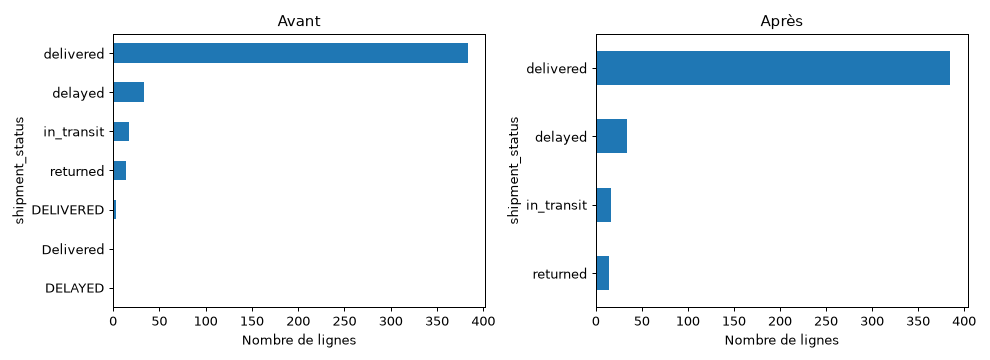

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, table, titre in [(axes[0], raw["shipments"], "Avant"),
                          (axes[1], clean["shipments"], "Après")]:
    table["shipment_status"].value_counts().sort_values().plot.barh(ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("Nombre de lignes")
plt.tight_layout()
plt.show()

## 8. Exporter les tables nettoyées

Nous avons supprimé 7 répétitions exactes et harmonisé les textes, les nombres et les dates. Les valeurs manquantes et les colonnes de prix et de devise sont conservées.

Les fichiers exportés serviront au notebook `EDA_logistics_anomalies.ipynb`.


In [11]:
dossier_sortie = Path("data_clean/logistics")
dossier_sortie.mkdir(parents=True, exist_ok=True)
for nom, table in clean.items():
    table.to_csv(dossier_sortie / f"{nom}.csv", index=False)

display(pd.DataFrame({
    "lignes_brutes": {nom: len(table) for nom, table in raw.items()},
    "lignes_nettoyees": {nom: len(table) for nom, table in clean.items()}
}))
print("Fichiers exportés dans", dossier_sortie)

,lignes_brutes,lignes_nettoyees
erp_business_partners,80,80
erp_facilities,30,30
goods_receipts,612,610
inventory_adjustments,140,140
inventory_month_end,502,500
purchase_order_lines,651,650
shipments,452,450


Fichiers exportés dans data_clean/logistics
